## Project Structure

Open the project root (`medical-appointment-noshow/`) in Visual Studio Code. Place `KaggleV2-May-2016.csv` in `data/raw/` before running this notebook.

```text
medical-appointment-noshow/
├── artifacts/                  # Plots logged to MLflow
├── data/
│   ├── raw/
│   │   └── KaggleV2-May-2016.csv   # Input dataset
│   └── processed/              # .npy arrays + dataset_metadata.json
├── logs/                       # Validation reports
├── mlruns/                     # MLflow artifact store
├── models/                     # Trained models
├── notebooks/
│   └── project_implementation.ipynb
├── outputs/                    # Error analysis + reports
├── pipelines/
│   ├── run_lab3_baseline.py
│   ├── run_lab4_tracking.py
│   ├── run_lab5_pipeline.py
│   └── run_lab6_registry.py
├── src/
│   ├── automate_lifecycle.py
│   ├── evaluate.py
│   ├── generate_registry_report.py
│   ├── preprocess.py
│   ├── train_mlflow.py
│   ├── train_registry.py
│   ├── train.py
│   ├── validate_data.py
│   ├── validate_outputs.py
│   └── validate_reproducibility.py
├── .gitignore
├── mlflow.db                   # Created by MLflow on first run
├── preprocess_pipeline.pkl     # Created by src/preprocess.py
└── requirements.txt
```


In [233]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\dhana\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


# 1. IMPORT REQUIRED LIBRARIES

This section imports all the required Python libraries and machine learning modules for data analysis, preprocessing, model building, evaluation, and visualization.

In [234]:
#1.IMPORT REQUIRED LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

# 2. LOAD THE DATASET

In this step, the dataset is loaded from the specified file path using Pandas. The `head()` function is used to display the first five rows of the dataset and verify that the data has been loaded successfully.

In [235]:
filepath = "../data/raw/KaggleV2-May-2016.csv"

df = pd.read_csv(filepath)

df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


# 3. BASIC DATASET UNDERSTANDING

In this step, the basic structure and statistical information of the dataset are examined. The `shape` function displays the number of rows and columns, `columns.tolist()` displays all column names, `info()` provides information about data types and missing values, and `describe()` generates descriptive statistics for the dataset.

In [236]:
#3.BASIC DATASET UNDERSTANDING

df.shape
df.columns.tolist()
df.info()
df.describe(include="all")

<class 'pandas.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  str    
 3   ScheduledDay    110527 non-null  str    
 4   AppointmentDay  110527 non-null  str    
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  str    
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  str    
dtypes: float64(1), int64(8), str(5)
memory usage: 11.8 MB


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
count,1.105270e+05,1.105270e+05,110527,110527,110527,110527.000000,110527,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527
unique,NaN,NaN,2,103549,27,NaN,81,NaN,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,F,2016-05-06T07:09:54Z,2016-06-06T00:00:00Z,NaN,JARDIM CAMBURI,NaN,NaN,NaN,NaN,NaN,NaN,No
freq,NaN,NaN,71840,24,4692,NaN,7717,NaN,NaN,NaN,NaN,NaN,NaN,88208
mean,1.474963e+14,5.675305e+06,NaN,NaN,NaN,37.088874,NaN,0.098266,0.197246,0.071865,0.030400,0.022248,0.321026,NaN
std,2.560949e+14,7.129575e+04,NaN,NaN,NaN,23.110205,NaN,0.297675,0.397921,0.258265,0.171686,0.161543,0.466873,NaN
min,3.921784e+04,5.030230e+06,NaN,NaN,NaN,-1.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
25%,4.172614e+12,5.640286e+06,NaN,NaN,NaN,18.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
50%,3.173184e+13,5.680573e+06,NaN,NaN,NaN,37.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
75%,9.439172e+13,5.725524e+06,NaN,NaN,NaN,55.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,NaN


# 4. CLEAN COLUMN NAMES

In this step, the column names are cleaned and standardized to make them easier to use during data analysis and machine learning. Extra spaces are removed, all column names are converted to lowercase, hyphens and spaces are replaced with underscores, and the cleaned column names are displayed.

In [237]:
#4.CLEAN COLUMN NAMES

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace("-", "_")
    .str.replace(" ", "_")
)

df.columns.tolist()

['patientid',
 'appointmentid',
 'gender',
 'scheduledday',
 'appointmentday',
 'age',
 'neighbourhood',
 'scholarship',
 'hipertension',
 'diabetes',
 'alcoholism',
 'handcap',
 'sms_received',
 'no_show']

# 5. CHECK FOR MISSING VALUES

In this step, the dataset is checked for missing values. The `isnull().sum()` function calculates the number of missing values in each column. The results are converted into a DataFrame for easier viewing and analysis.

In [238]:
missing_values=df.isnull().sum()

missing_df=missing_values.to_frame("missing_values")

missing_df

,missing_values
patientid,0
appointmentid,0
gender,0
scheduledday,0
appointmentday,0
age,0
neighbourhood,0
scholarship,0
hipertension,0
diabetes,0


# 6. DUPLICATE ANALYSIS

In this step, the dataset is checked for duplicate rows. The `duplicated()` function identifies duplicate records, and `sum()` calculates the total number of duplicate rows present in the dataset.

In [239]:
#6.DUPLICATE ANALYSIS

duplicate_count=df.duplicated().sum()

duplicate_count

0

# 6. REMOVE DUPLICATE ROWS

In this step, duplicate rows are removed from the dataset using the `drop_duplicates()` function. The shape of the dataset is then displayed to verify the number of rows and columns remaining after removing duplicates.

In [240]:
#Remove duplicate rows
df=df.drop_duplicates()

#Display shape after removing duplicates
df.shape

(110527, 14)

# 7. TARGET VARIABLE ANALYSIS

In this step, the target variable `no_show` is analyzed to understand the distribution of the target classes. The `value_counts()` function calculates the number of observations in each class, while `value_counts(normalize=True)` calculates their percentage distribution.

In [241]:
#7.TARGET VARIABLE ANALYSIS

target_counts=df["no_show"].value_counts()
target_percentage=df["no_show"].value_counts(normalize=True) * 100

target_counts

no_show
No     88208
Yes    22319
Name: count, dtype: int64

# 7. VISUALIZE TARGET VARIABLE DISTRIBUTION

In this step, a count plot is used to visualize the distribution of the target variable `no_show`. The plot shows the number of patients in each category, making it easier to understand the class distribution of appointment attendance.

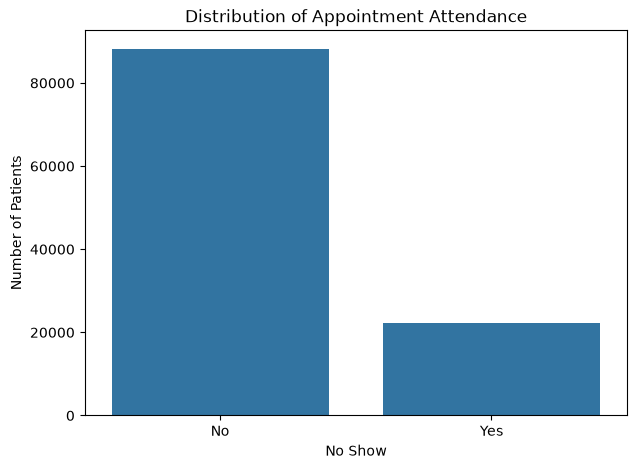

In [242]:
plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x="no_show"
)
plt.title("Distribution of Appointment Attendance")
plt.xlabel("No Show")
plt.ylabel("Number of Patients")

plt.show()

# 8. TARGET VARIABLE VISUALIZATION

In this step, the target variable `no_show` is visualized using a count plot. The plot displays the number of patients in each target category and helps identify whether the dataset is balanced or imbalanced.

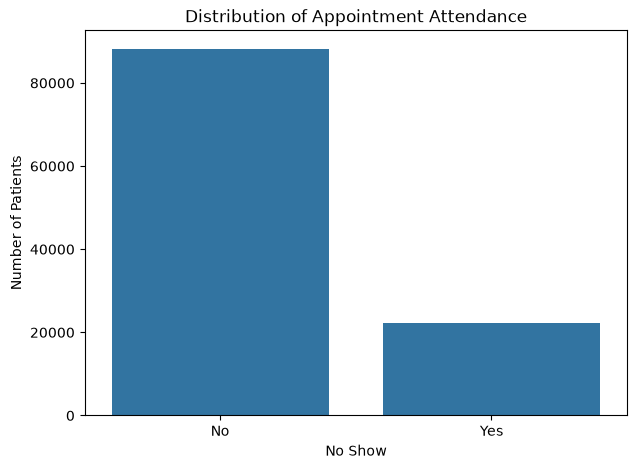

In [243]:
#8.TARGET VARIABLE VISUALIZATION

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="no_show")

plt.title("Distribution of Appointment Attendance")
plt.xlabel("No Show")
plt.ylabel("Number of Patients")

plt.show()

# 8. AGE VALIDATION

In this step, the `age` column is converted into a numeric data type using `pd.to_numeric()`. Any invalid or non-numeric values are converted to missing values using `errors="coerce"`. Records with negative ages are removed because age cannot be negative. The shape of the dataset is then displayed to verify the remaining rows and columns.

In [244]:
#AGE VALIDATION

df["age"]=pd.to_numeric(df["age"], errors="coerce")

df=df[df["age"] >= 0].copy()

df.shape

(110526, 14)

# 9. UNIQUE VALUE ANALYSIS

In this step, the unique values present in each column are analyzed. The `unique()` function retrieves the unique values from each column, while `[:20]` limits the output to the first 20 unique values. The results are organized into a DataFrame for easier comparison and understanding of the dataset.

In [245]:
#9.UNIQUE VALUE ANALYSIS

unique_values=pd.DataFrame({
    column: pd.Series(df[column].unique()[:20])
    for column in df.columns
})

unique_values

,patientid,appointmentid,gender,scheduledday,appointmentday,age,neighbourhood,scholarship,hipertension,diabetes,alcoholism,handcap,sms_received,no_show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0.0,1.0,0.0,0.0,0.0,0.0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-05-03T00:00:00Z,56,MATA DA PRAIA,1.0,0.0,1.0,1.0,1.0,1.0,Yes
2,4.262962e+12,5642549,NaN,2016-04-29T16:19:04Z,2016-05-10T00:00:00Z,8,PONTAL DE CAMBURI,NaN,NaN,NaN,NaN,2.0,NaN,NaN
3,8.679512e+11,5642828,NaN,2016-04-29T17:29:31Z,2016-05-17T00:00:00Z,76,REPÚBLICA,NaN,NaN,NaN,NaN,3.0,NaN,NaN
4,8.841186e+12,5642494,NaN,2016-04-29T16:07:23Z,2016-05-24T00:00:00Z,23,GOIABEIRAS,NaN,NaN,NaN,NaN,4.0,NaN,NaN
5,9.598513e+13,5626772,NaN,2016-04-27T08:36:51Z,2016-05-31T00:00:00Z,39,ANDORINHAS,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,7.336882e+14,5630279,NaN,2016-04-27T15:05:12Z,2016-05-02T00:00:00Z,21,CONQUISTA,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,3.449833e+12,5630575,NaN,2016-04-27T15:39:58Z,2016-05-30T00:00:00Z,19,NOVA PALESTINA,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,5.639473e+13,5638447,NaN,2016-04-29T08:02:16Z,2016-05-16T00:00:00Z,30,DA PENHA,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,7.812456e+13,5629123,NaN,2016-04-27T12:48:25Z,2016-05-04T00:00:00Z,29,TABUAZEIRO,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 9. DISPLAY COLUMN NAMES

In this step, the column names of the dataset are displayed using `columns.tolist()`. This helps verify the cleaned and standardized column names before continuing with further data preprocessing and analysis.

In [246]:
df.columns.tolist()

['patientid',
 'appointmentid',
 'gender',
 'scheduledday',
 'appointmentday',
 'age',
 'neighbourhood',
 'scholarship',
 'hipertension',
 'diabetes',
 'alcoholism',
 'handcap',
 'sms_received',
 'no_show']

# 10. DATE CONVERSION

In this step, the `scheduledday` and `appointmentday` columns are converted into datetime format using `pd.to_datetime()`. Invalid date values are converted to missing values using `errors="coerce"`. The first five rows of both columns are displayed to verify the conversion.

In [247]:
#10.DATE CONVERSION

df["scheduledday"] = pd.to_datetime(df["scheduledday"], errors="coerce")
df["appointmentday"] = pd.to_datetime(df["appointmentday"], errors="coerce")

df[["scheduledday", "appointmentday"]].head()

,scheduledday,appointmentday
0,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00
1,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00
2,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00
3,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00
4,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00


# 11. DATE FEATURE EXTRACTION

In this step, useful features are extracted from the `appointmentday` and `scheduledday` columns. The year, month, day, and day of the week are extracted from the appointment date. The `waiting_days` feature calculates the number of days between the scheduled date and the appointment date. These newly created features are displayed along with the original date columns for verification.

In [248]:
#11.DATE FEATURE EXTRACTION

df["appointment_year"] = df["appointmentday"].dt.year

df["appointment_month"] = df["appointmentday"].dt.month

df["appointment_day"] = df["appointmentday"].dt.day

df["appointment_dayofweek"] = df["appointmentday"].dt.dayofweek

df["waiting_days"] = (
    df["appointmentday"].dt.normalize() -
    df["scheduledday"].dt.normalize()
).dt.days

df[
    [
        "scheduledday",
        "appointmentday",
        "appointment_year",
        "appointment_month",
        "appointment_day",
        "appointment_dayofweek",
        "waiting_days"
    ]
].head()

,scheduledday,appointmentday,appointment_year,appointment_month,appointment_day,appointment_dayofweek,waiting_days
0,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,2016,4,29,4,0
1,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,2016,4,29,4,0
2,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,2016,4,29,4,0
3,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,2016,4,29,4,0
4,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,2016,4,29,4,0


# 12. CHECK AND HANDLE INVALID VALUES

In this step, the dataset is checked for missing values, duplicate rows, invalid age values, and negative waiting days. The `describe()` function is used to obtain statistical information about the `age` column. Duplicate rows are removed, ages are restricted to the valid range of 0 to 100 years, and records with negative waiting days are removed. Finally, the results and the updated dataset shape are displayed.

In [249]:
#12.CHECK AND HANDLE INVALID VALUES

missing_values = df.isnull().sum()
duplicate_rows = df.duplicated().sum()
age_statistics = df["age"].describe()
negative_waiting_days = (df["waiting_days"] < 0).sum()

df = df.drop_duplicates()

df = df[(df["age"] >= 0) & (df["age"] <= 100)]

df = df[df["waiting_days"] >= 0]

# Display results
missing_values
duplicate_rows
age_statistics
negative_waiting_days
df.shape

(110514, 19)

# 13. CHECK DATA TYPES

In this step, the data types of all columns in the dataset are checked using the `dtypes` attribute. This helps verify that each column has the appropriate data type before proceeding with further data preprocessing and model building.

In [250]:
#13.CHECK DATA TYPES

df.dtypes

patientid                            float64
appointmentid                          int64
gender                                   str
scheduledday             datetime64[us, UTC]
appointmentday           datetime64[us, UTC]
age                                    int64
neighbourhood                            str
scholarship                            int64
hipertension                           int64
diabetes                               int64
alcoholism                             int64
handcap                                int64
sms_received                           int64
no_show                                  str
appointment_year                       int32
appointment_month                      int32
appointment_day                        int32
appointment_dayofweek                  int32
waiting_days                           int64
dtype: object

# 14. CHECK TARGET VARIABLE

In this step, the target variable `no_show` is examined to understand its unique values and class distribution. The `unique()` function identifies the different target classes, `value_counts()` calculates the number of observations in each class, and `value_counts(normalize=True)` calculates the percentage distribution of each class.

In [251]:
#14.CHECK TARGET VARIABLE

target_unique = df["no_show"].unique()
target_counts = df["no_show"].value_counts()
target_percentage = df["no_show"].value_counts(normalize=True) * 100

display(target_unique)
display(target_counts)
display(target_percentage)

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

no_show
No     88203
Yes    22311
Name: count, dtype: int64

no_show
No     79.811608
Yes    20.188392
Name: proportion, dtype: float64

# 15. CONVERT TARGET VARIABLE

In this step, the target variable `no_show` is converted from categorical values into numerical values. The value `"No"` is mapped to `0`, while `"Yes"` is mapped to `1`. This numerical representation is required for classification model training. The value counts and unique values are then displayed to verify the conversion.

In [252]:
#15.CONVERT TARGET VARIABLE

df["no_show"] = df["no_show"].map({
    "No": 0,
    "Yes": 1
})

display(df["no_show"].value_counts())
display(df["no_show"].unique())

no_show
0    88203
1    22311
Name: count, dtype: int64

array([0, 1], dtype=int64)

# 16. ENCODE GENDER

In this step, the categorical `gender` variable is converted into numerical values. The value `"F"` is mapped to `0`, while `"M"` is mapped to `1`. This encoding converts the categorical data into a numerical format suitable for machine learning models. The value counts are displayed to verify the conversion.

In [253]:
#16.ENCODE GENDER

df["gender"] = df["gender"].map({
    "F": 0,
    "M": 1
})

df["gender"].value_counts()

gender
0    71829
1    38685
Name: count, dtype: int64

# 17. CHECK NEIGHBOURHOOD

In this step, the `neighbourhood` column is examined to understand its categorical values. The `nunique()` function calculates the total number of unique neighbourhoods, while the `unique()` function displays all the distinct neighbourhood names.

In [254]:
#17.CHECK NEIGHBOURHOOD

display(df["neighbourhood"].nunique())
display(df["neighbourhood"].unique())

81

<StringArray>
[            'JARDIM DA PENHA',               'MATA DA PRAIA',
           'PONTAL DE CAMBURI',                   'REPÚBLICA',
                  'GOIABEIRAS',                  'ANDORINHAS',
                   'CONQUISTA',              'NOVA PALESTINA',
                    'DA PENHA',                  'TABUAZEIRO',
              'BENTO FERREIRA',                   'SÃO PEDRO',
                'SANTA MARTHA',               'SÃO CRISTÓVÃO',
                     'MARUÍPE',              'GRANDE VITÓRIA',
                'SÃO BENEDITO',           'ILHA DAS CAIEIRAS',
                 'SANTO ANDRÉ',                'SOLON BORGES',
                      'BONFIM',              'JARDIM CAMBURI',
                 'MARIA ORTIZ',                      'JABOUR',
             'ANTÔNIO HONÓRIO',                 'RESISTÊNCIA',
         'ILHA DE SANTA MARIA',                 'JUCUTUQUARA',
                  'MONTE BELO',              'MÁRIO CYPRESTE',
               'SANTO ANTÔNIO',          

# 18. REMOVE UNNECESSARY COLUMNS

In this step, unnecessary columns that are not required for model training are removed from the dataset. The `patientid` and `appointmentid` columns are identifiers, while `scheduledday` and `appointmentday` are removed because useful date-based features have already been extracted from them. The remaining column names are then displayed for verification.

In [255]:
#18.REMOVE UNNECESSARY COLUMNS

columns_to_drop = [
    "patientid",
    "appointmentid",
    "scheduledday",
    "appointmentday"
]

df = df.drop(columns=columns_to_drop)

#Display remaining columns
df_remaining_columns = pd.DataFrame({
    "Remaining Columns": df.columns.tolist()
})

df_remaining_columns

,Remaining Columns
0,gender
1,age
2,neighbourhood
3,scholarship
4,hipertension
5,diabetes
6,alcoholism
7,handcap
8,sms_received
9,no_show


# 19. CHECK CLEANED DATASET

In this step, the cleaned dataset is checked to ensure that the preprocessing operations have been performed correctly. The `head()` function displays the first five rows, `info()` provides information about the columns and their data types, and `isnull().sum()` checks for any remaining missing values.

In [256]:
#19.CHECK CLEANED DATASET

display(df.head())

df.info()

display(df.isnull().sum())

,gender,age,neighbourhood,scholarship,hipertension,diabetes,alcoholism,handcap,sms_received,no_show,appointment_year,appointment_month,appointment_day,appointment_dayofweek,waiting_days
0,0,62,JARDIM DA PENHA,0,1,0,0,0,0,0,2016,4,29,4,0
1,1,56,JARDIM DA PENHA,0,0,0,0,0,0,0,2016,4,29,4,0
2,0,62,MATA DA PRAIA,0,0,0,0,0,0,0,2016,4,29,4,0
3,0,8,PONTAL DE CAMBURI,0,0,0,0,0,0,0,2016,4,29,4,0
4,0,56,JARDIM DA PENHA,0,1,1,0,0,0,0,2016,4,29,4,0


<class 'pandas.DataFrame'>
Index: 110514 entries, 0 to 110526
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype
---  ------                 --------------   -----
 0   gender                 110514 non-null  int64
 1   age                    110514 non-null  int64
 2   neighbourhood          110514 non-null  str  
 3   scholarship            110514 non-null  int64
 4   hipertension           110514 non-null  int64
 5   diabetes               110514 non-null  int64
 6   alcoholism             110514 non-null  int64
 7   handcap                110514 non-null  int64
 8   sms_received           110514 non-null  int64
 9   no_show                110514 non-null  int64
 10  appointment_year       110514 non-null  int32
 11  appointment_month      110514 non-null  int32
 12  appointment_day        110514 non-null  int32
 13  appointment_dayofweek  110514 non-null  int32
 14  waiting_days           110514 non-null  int64
dtypes: int32(4), int64(10), str(1)
me

gender                   0
age                      0
neighbourhood            0
scholarship              0
hipertension             0
diabetes                 0
alcoholism               0
handcap                  0
sms_received             0
no_show                  0
appointment_year         0
appointment_month        0
appointment_day          0
appointment_dayofweek    0
waiting_days             0
dtype: int64

# 20. CHECK NUMERICAL FEATURES

In this step, the numerical features present in the dataset are identified using `select_dtypes()`. The `columns.tolist()` function displays the names of the numerical columns. The `describe()` function is then used to generate descriptive statistics such as count, mean, standard deviation, minimum, maximum, and quartile values for the numerical features.

In [257]:
#20.CHECK NUMERICAL FEATURES

display(df.select_dtypes(include=["int64", "float64"]).columns.tolist())

display(df.describe())

['gender',
 'age',
 'scholarship',
 'hipertension',
 'diabetes',
 'alcoholism',
 'handcap',
 'sms_received',
 'no_show',
 'waiting_days']

,gender,age,scholarship,hipertension,diabetes,alcoholism,handcap,sms_received,no_show,appointment_year,appointment_month,appointment_day,appointment_dayofweek,waiting_days
count,110514.000000,110514.000000,110514.000000,110514.000000,110514.000000,110514.000000,110514.000000,110514.000000,110514.000000,110514.0,110514.000000,110514.000000,110514.000000,110514.000000
mean,0.350046,37.084686,0.098277,0.197260,0.071873,0.030403,0.022196,0.321054,0.201884,2016.0,5.210046,12.499638,1.858271,10.184438
std,0.476986,23.103024,0.297690,0.397932,0.258279,0.171695,0.161391,0.466884,0.401408,0.0,0.473786,9.056521,1.371668,15.255288
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2016.0,4.000000,1.000000,0.000000,0.000000
25%,0.000000,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2016.0,5.000000,5.000000,1.000000,0.000000
50%,0.000000,37.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2016.0,5.000000,10.000000,2.000000,4.000000
75%,1.000000,55.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,2016.0,5.000000,19.000000,3.000000,15.000000
max,1.000000,100.000000,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000,1.000000,2016.0,6.000000,31.000000,5.000000,179.000000


# 21. SEPARATE FEATURES AND TARGET

In this step, the dataset is divided into input features and the target variable. The `no_show` column is separated as the target variable `y`, while all remaining columns are stored as input features `X`. The feature names, target name, and their respective shapes are displayed to verify the separation.

In [258]:
#21.SEPARATE FEATURES AND TARGET

X = df.drop("no_show", axis=1)

y = df["no_show"]

display(X.columns.tolist())
display(y.name)
display(X.shape)
display(y.shape)

['gender',
 'age',
 'neighbourhood',
 'scholarship',
 'hipertension',
 'diabetes',
 'alcoholism',
 'handcap',
 'sms_received',
 'appointment_year',
 'appointment_month',
 'appointment_day',
 'appointment_dayofweek',
 'waiting_days']

'no_show'

(110514, 14)

(110514,)

# 22. CHECK TARGET DISTRIBUTION

In this step, the distribution of the target variable `y` is analyzed. The `value_counts()` function displays the number of observations in each target class, while `value_counts(normalize=True)` calculates the percentage distribution of each class. The percentages are rounded to two decimal places for easier interpretation.

In [259]:
#22.CHECK TARGET DISTRIBUTION

display(y.value_counts())

display((y.value_counts(normalize=True) * 100).round(2))

no_show
0    88203
1    22311
Name: count, dtype: int64

no_show
0    79.81
1    20.19
Name: proportion, dtype: float64

# 23. TRAIN-TEST SPLIT

In this step, the dataset is divided into training and testing sets using `train_test_split()`. First, the target variable is checked for missing values and its class distribution is displayed. The features and target are then separated into `X` and `y`. The dataset is split into 80% training data and 20% testing data. `random_state=42` ensures reproducibility, while `stratify=y` maintains the same target class distribution in both training and testing sets. Finally, the shapes of the training and testing datasets are displayed.

In [260]:
#23.TRAIN-TEST SPLIT

from sklearn.model_selection import train_test_split

#Check target values
display(df["no_show"].value_counts(dropna=False))

#Create X and y
X = df.drop("no_show", axis=1)
y = df["no_show"]

display(y.isnull().sum())

display(X.shape)
display(y.shape)

#Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

#Display train and test shapes
display(X_train.shape)
display(X_test.shape)
display(y_train.shape)
display(y_test.shape)

no_show
0    88203
1    22311
Name: count, dtype: int64

0

(110514, 14)

(110514,)

(88411, 14)

(22103, 14)

(88411,)

(22103,)

# 24. PREPROCESSING

In this step, the preprocessing pipeline is created for numerical and categorical features. The `neighbourhood` column is treated as a categorical feature and encoded using `OneHotEncoder`. The numerical features are standardized using `StandardScaler` so that they have a comparable scale. A `ColumnTransformer` is used to apply the appropriate preprocessing technique to each type of feature. The categorical and numerical feature lists are displayed for verification.

In [261]:
#24.PREPROCESSING

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

#Categorical column
categorical_features = ["neighbourhood"]

#Numerical columns
numerical_features = [
    "gender",
    "age",
    "scholarship",
    "hipertension",
    "diabetes",
    "alcoholism",
    "handcap",
    "sms_received",
    "appointment_year",
    "appointment_month",
    "appointment_day",
    "appointment_dayofweek",
    "waiting_days"
]

#Preprocessing for numerical and categorical data
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

display(categorical_features)
display(numerical_features)

['neighbourhood']

['gender',
 'age',
 'scholarship',
 'hipertension',
 'diabetes',
 'alcoholism',
 'handcap',
 'sms_received',
 'appointment_year',
 'appointment_month',
 'appointment_day',
 'appointment_dayofweek',
 'waiting_days']

# 25. APPLY PREPROCESSING

In this step, the preprocessing transformations defined earlier are applied to the training and testing datasets. The `fit_transform()` method is used on the training data to learn and apply the transformations, while `transform()` is used on the testing data using the same transformations. The original and processed shapes are displayed to verify the preprocessing results.

In [262]:
#25.APPLY PREPROCESSING

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

display(X_train.shape)
display(X_train_processed.shape)

display(X_test.shape)
display(X_test_processed.shape)

(88411, 14)

(88411, 94)

(22103, 14)

(22103, 94)

# 26. VERIFY PROCESSED DATA

In this step, the processed training and testing feature data are verified by checking their data types. The target variable distributions for the training and testing datasets are also displayed to ensure that the class distribution is maintained after the train-test split.

In [263]:
#26.VERIFY PROCESSED DATA

display(type(X_train_processed))

display(type(X_test_processed))

display(y_train.value_counts())

display(y_test.value_counts())

scipy.sparse._csr.csr_matrix

scipy.sparse._csr.csr_matrix

no_show
0    70562
1    17849
Name: count, dtype: int64

no_show
0    17641
1     4462
Name: count, dtype: int64

# 27. TRAIN LOGISTIC REGRESSION MODEL

In this step, a Logistic Regression classification model is created and trained using the preprocessed training data. The `max_iter=1000` parameter allows sufficient iterations for the model to converge, while `random_state=42` ensures reproducible results. After training, a DataFrame is created to display the model name and training status.

In [264]:
#27.TRAIN LOGISTIC REGRESSION MODEL

from sklearn.linear_model import LogisticRegression

#Create the model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

#Train the model
logistic_model.fit(X_train_processed, y_train)

#Display model training result using DataFrame
df_logistic = pd.DataFrame({
    "Model": ["Logistic Regression"],
    "Status": ["Model trained successfully"]
})

df_logistic

,Model,Status
0,Logistic Regression,Model trained successfully


# 28. MAKE PREDICTIONS

In this step, the trained Logistic Regression model is used to predict the target values for the test dataset. The predicted values are stored in `y_pred_lr`. A DataFrame is then created to compare the first 20 actual target values with their corresponding predicted values.

In [265]:
#28.MAKE PREDICTIONS

y_pred_lr = logistic_model.predict(X_test_processed)

# Create DataFrame with actual and predicted values
df_predictions_lr = pd.DataFrame({
    "Actual": y_test.head(20).values,
    "Predicted": y_pred_lr[:20]
})

df_predictions_lr

,Actual,Predicted
0,1,0
1,0,0
2,0,0
3,0,0
4,0,0
5,0,0
6,0,0
7,0,0
8,1,0
9,0,0


# 29. EVALUATE LOGISTIC REGRESSION

In this step, the performance of the Logistic Regression model is evaluated using Accuracy, Precision, Recall, and F1 Score. These metrics measure different aspects of the model's classification performance. The calculated metrics are rounded to four decimal places and stored in a DataFrame for easy comparison.

In [266]:
#29.EVALUATE LOGISTIC REGRESSION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

#Calculate evaluation metrics
accuracy_lr = accuracy_score(y_test, y_pred_lr)

precision_lr = precision_score(
    y_test,
    y_pred_lr,
    zero_division=0
)

recall_lr = recall_score(
    y_test,
    y_pred_lr,
    zero_division=0
)

f1_lr = f1_score(
    y_test,
    y_pred_lr,
    zero_division=0
)

#Create DataFrame for performance metrics
df_logistic_performance = pd.DataFrame({
    "Model": ["Logistic Regression"],
    "Accuracy": [round(accuracy_lr, 4)],
    "Precision": [round(precision_lr, 4)],
    "Recall": [round(recall_lr, 4)],
    "F1 Score": [round(f1_lr, 4)]
})

df_logistic_performance

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.795,0.3365,0.0159,0.0304


# 29. CLASSIFICATION REPORT

The classification report provides a detailed evaluation of the Logistic Regression model for each target class. It includes Precision, Recall, F1 Score, and Support. The report is generated as a dictionary using `output_dict=True` and then converted into a DataFrame for easier interpretation.

In [267]:
#Classification Report

report_lr = classification_report(
    y_test,
    y_pred_lr,
    target_names=["Show", "No Show"],
    zero_division=0,
    output_dict=True
)

df_classification_lr = pd.DataFrame(report_lr).transpose()

df_classification_lr

,precision,recall,f1-score,support
Show,0.799424,0.992064,0.885387,17641.000000
No Show,0.336493,0.015912,0.030387,4462.000000
accuracy,0.795005,0.795005,0.795005,0.795005
macro avg,0.567959,0.503988,0.457887,22103.000000
weighted avg,0.705971,0.795005,0.712786,22103.000000


# 30. CONFUSION MATRIX

In this step, a confusion matrix is generated to evaluate the classification performance of the Logistic Regression model. It compares the actual target values with the predicted values and shows the number of correct and incorrect predictions for each class. The confusion matrix is converted into a DataFrame with descriptive row and column labels for easier interpretation.

In [268]:
#30.CONFUSION MATRIX

from sklearn.metrics import confusion_matrix

cm_lr = confusion_matrix(y_test, y_pred_lr)

# Convert confusion matrix into DataFrame
df_confusion_lr = pd.DataFrame(
    cm_lr,
    index=["Actual Show", "Actual No Show"],
    columns=["Predicted Show", "Predicted No Show"]
)

df_confusion_lr

,Predicted Show,Predicted No Show
Actual Show,17501,140
Actual No Show,4391,71


# 30. PLOT CONFUSION MATRIX

In this step, the confusion matrix of the Logistic Regression model is visualized using `ConfusionMatrixDisplay`. The plot shows the actual and predicted classes, making it easier to identify correct and incorrect classifications for the `Show` and `No Show` categories.

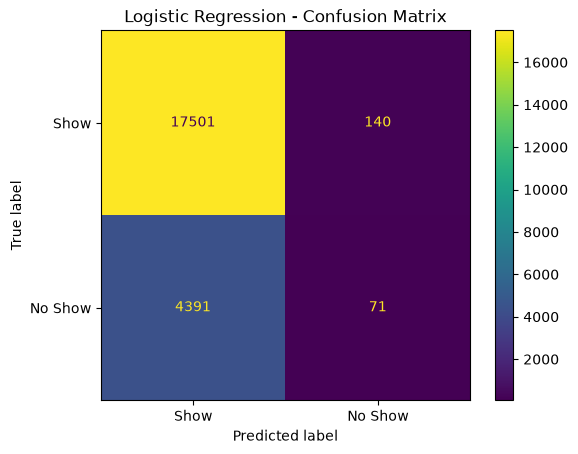

In [269]:
#Plot Confusion Matrix

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Show", "No Show"]
)

disp.plot()

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

# 31. TRAIN DECISION TREE MODEL

In this step, a Decision Tree classification model is created and trained using the preprocessed training data. The `max_depth=10` parameter limits the maximum depth of the tree to help control model complexity, while `random_state=42` ensures reproducible results. After training, a DataFrame is created to display the model name and training status.

In [270]:
#31.TRAIN DECISION TREE MODEL

from sklearn.tree import DecisionTreeClassifier

#Create Decision Tree model
decision_tree_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

#Train the model
decision_tree_model.fit(
    X_train_processed,
    y_train
)

#Display training result using DataFrame
df_decision_tree = pd.DataFrame({
    "Model": ["Decision Tree"],
    "Status": ["Model trained successfully"]
})

df_decision_tree

,Model,Status
0,Decision Tree,Model trained successfully


# 32. MAKE PREDICTIONS

In this step, the trained Decision Tree model is used to predict the target values for the test dataset. The predicted values are stored in `y_pred_dt`. A DataFrame is then created to compare the first 20 actual target values with their corresponding predicted values.

In [271]:
#32.MAKE PREDICTIONS

y_pred_dt = decision_tree_model.predict(X_test_processed)

# Create DataFrame with actual and predicted values
df_predictions_dt = pd.DataFrame({
    "Actual": y_test.head(20).values,
    "Predicted": y_pred_dt[:20]
})

df_predictions_dt

,Actual,Predicted
0,1,0
1,0,0
2,0,0
3,0,0
4,0,0
5,0,0
6,0,0
7,0,0
8,1,0
9,0,0


# 33. EVALUATE DECISION TREE

In this step, the performance of the Decision Tree model is evaluated using Accuracy, Precision, Recall, and F1 Score. These metrics help measure the model's classification performance. The calculated values are rounded to four decimal places and stored in a DataFrame for easy interpretation and comparison.

In [272]:
#33.EVALUATE DECISION TREE

accuracy_dt = accuracy_score(
    y_test,
    y_pred_dt
)

precision_dt = precision_score(
    y_test,
    y_pred_dt,
    zero_division=0
)

recall_dt = recall_score(
    y_test,
    y_pred_dt,
    zero_division=0
)

f1_dt = f1_score(
    y_test,
    y_pred_dt,
    zero_division=0
)

#Create DataFrame for model performance
df_decision_tree_performance = pd.DataFrame({
    "Model": ["Decision Tree"],
    "Accuracy": [round(accuracy_dt, 4)],
    "Precision": [round(precision_dt, 4)],
    "Recall": [round(recall_dt, 4)],
    "F1 Score": [round(f1_dt, 4)]
})

df_decision_tree_performance

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.7961,0.452,0.0464,0.0841


# 34. CONFUSION MATRIX - DECISION TREE

In this step, a confusion matrix is generated to evaluate the classification performance of the Decision Tree model. It compares the actual target values with the predicted values and shows the number of correct and incorrect predictions for each class. The confusion matrix is converted into a DataFrame with descriptive row and column labels for easier interpretation.

In [273]:
#34.CONFUSION MATRIX - DECISION TREE

cm_dt = confusion_matrix(
    y_test,
    y_pred_dt
)

#Convert confusion matrix into DataFrame
df_confusion_dt = pd.DataFrame(
    cm_dt,
    index=["Actual Show", "Actual No Show"],
    columns=["Predicted Show", "Predicted No Show"]
)

df_confusion_dt

,Predicted Show,Predicted No Show
Actual Show,17390,251
Actual No Show,4255,207


# 34. PLOT DECISION TREE CONFUSION MATRIX

In this step, the confusion matrix of the Decision Tree model is displayed as a DataFrame. It shows the actual and predicted values for the `Show` and `No Show` classes, helping to identify the correct and incorrect predictions made by the model.

In [274]:
#Plot Decision Tree Confusion Matrix

#Create DataFrame
df_confusion_dt = pd.DataFrame(
    cm_dt,
    index=["Actual Show", "Actual No Show"],
    columns=["Predicted Show", "Predicted No Show"]
)

#Display DataFrame
df_confusion_dt

,Predicted Show,Predicted No Show
Actual Show,17390,251
Actual No Show,4255,207


# 34. PLOT DECISION TREE CONFUSION MATRIX

In this step, the confusion matrix of the Decision Tree model is visualized using `ConfusionMatrixDisplay`. The plot displays the actual and predicted classes, making it easier to identify the correct and incorrect classifications made by the Decision Tree model.

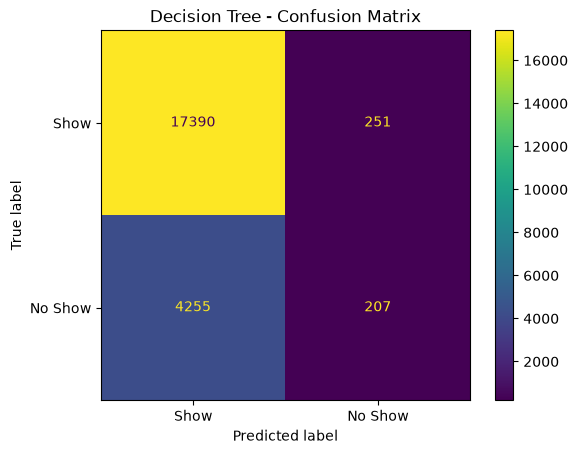

In [275]:
#Plot Decision Tree Confusion Matrix

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["Show", "No Show"]
)

disp.plot()

plt.title("Decision Tree - Confusion Matrix")
plt.show()

# 35. MODEL COMPARISON

In this step, the performance of the Logistic Regression and Decision Tree models is compared using Accuracy, Precision, Recall, and F1 Score. The evaluation results of both models are combined into a single DataFrame, and the values are rounded to four decimal places for easier comparison.

In [276]:
#35.MODEL COMPARISON

model_comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],

    "Accuracy": [
        accuracy_lr,
        accuracy_dt
    ],

    "Precision": [
        precision_lr,
        precision_dt
    ],

    "Recall": [
        recall_lr,
        recall_dt
    ],

    "F1 Score": [
        f1_lr,
        f1_dt
    ]
})

#Round the values
model_comparison = model_comparison.round(4)

#Display DataFrame
model_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.7950,0.3365,0.0159,0.0304
1,Decision Tree,0.7961,0.4520,0.0464,0.0841


# 36. TRAIN RANDOM FOREST MODEL

In this step, a Random Forest classification model is created and trained using the preprocessed training data. The `n_estimators=100` parameter specifies the number of decision trees in the forest, while `max_depth=10` limits the maximum depth of each tree to control model complexity. The `random_state=42` ensures reproducible results, and `n_jobs=-1` allows the model to use all available processor cores for faster training. The training status is then displayed using a DataFrame.

In [277]:
#36.TRAIN RANDOM FOREST MODEL

from sklearn.ensemble import RandomForestClassifier

#Create Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

#Train the model
random_forest_model.fit(
    X_train_processed,
    y_train
)

#Display training status using DataFrame
df_random_forest = pd.DataFrame({
    "Model": ["Random Forest"],
    "Status": ["Model trained successfully"]
})

df_random_forest

,Model,Status
0,Random Forest,Model trained successfully


# 37. MAKE PREDICTIONS

In this step, the trained Random Forest model is used to predict the target values for the test dataset. The predicted values are stored in `y_pred_rf`. A DataFrame is then created to compare the first 20 actual target values with their corresponding predicted values.

In [278]:
#37.MAKE PREDICTIONS

y_pred_rf = random_forest_model.predict(X_test_processed)

#Create DataFrame with actual and predicted values
df_predictions_rf = pd.DataFrame({
    "Actual": y_test.head(20).values,
    "Predicted": y_pred_rf[:20]
})

df_predictions_rf

,Actual,Predicted
0,1,0
1,0,0
2,0,0
3,0,0
4,0,0
5,0,0
6,0,0
7,0,0
8,1,0
9,0,0


# 38. EVALUATE RANDOM FOREST

In this step, the performance of the Random Forest model is evaluated using Accuracy, Precision, Recall, and F1 Score. These metrics help measure the model's classification performance on the test dataset. The calculated values are rounded to four decimal places and stored in a DataFrame for easy interpretation and comparison with other models.

In [279]:
#38.EVALUATE RANDOM FOREST

accuracy_rf = accuracy_score(
    y_test,
    y_pred_rf
)

precision_rf = precision_score(
    y_test,
    y_pred_rf,
    zero_division=0
)

recall_rf = recall_score(
    y_test,
    y_pred_rf,
    zero_division=0
)

f1_rf = f1_score(
    y_test,
    y_pred_rf,
    zero_division=0
)

#Create DataFrame for performance metrics
df_random_forest_performance = pd.DataFrame({
    "Model": ["Random Forest"],
    "Accuracy": [round(accuracy_rf, 4)],
    "Precision": [round(precision_rf, 4)],
    "Recall": [round(recall_rf, 4)],
    "F1 Score": [round(f1_rf, 4)]
})

df_random_forest_performance

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.7981,0.0,0.0,0.0


# 39. CONFUSION MATRIX - RANDOM FOREST

In this step, a confusion matrix is generated to evaluate the classification performance of the Random Forest model. It compares the actual target values with the predicted values and shows the number of correct and incorrect predictions for the `Show` and `No Show` classes. The confusion matrix is converted into a DataFrame with descriptive row and column labels for easier interpretation.

In [280]:
#39.CONFUSION MATRIX - RANDOM FOREST

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

#Convert confusion matrix into DataFrame
df_confusion_rf = pd.DataFrame(
    cm_rf,
    index=["Actual Show", "Actual No Show"],
    columns=["Predicted Show", "Predicted No Show"]
)

df_confusion_rf

,Predicted Show,Predicted No Show
Actual Show,17641,0
Actual No Show,4462,0


# 39. PLOT RANDOM FOREST CONFUSION MATRIX

In this step, the confusion matrix of the Random Forest model is visualized using `ConfusionMatrixDisplay`. The visualization shows the actual and predicted classes, making it easier to identify correct and incorrect classifications for the `Show` and `No Show` categories.

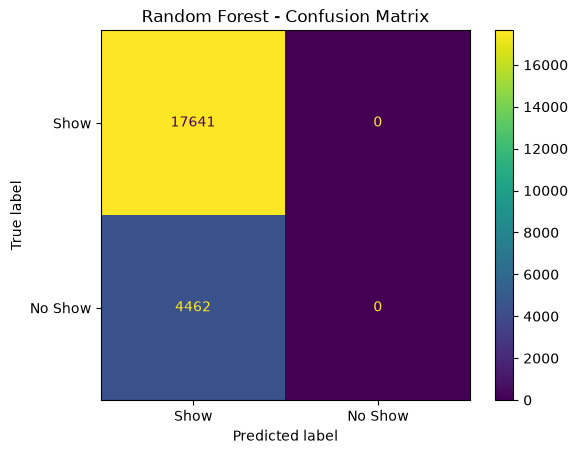

In [281]:
#Plot Random Forest Confusion Matrix

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Show", "No Show"]
)

disp.plot()

plt.title("Random Forest - Confusion Matrix")
plt.show()

# 40. MODEL COMPARISON

In this step, the performance of the Logistic Regression, Decision Tree, and Random Forest models is compared using Accuracy, Precision, Recall, and F1 Score. The evaluation results of all three models are combined into a single DataFrame. The values are rounded to four decimal places to make the comparison clear and easy to interpret.

In [282]:
#40.MODEL COMPARISON

model_comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_lr,
        accuracy_dt,
        accuracy_rf
    ],

    "Precision": [
        precision_lr,
        precision_dt,
        precision_rf
    ],

    "Recall": [
        recall_lr,
        recall_dt,
        recall_rf
    ],

    "F1 Score": [
        f1_lr,
        f1_dt,
        f1_rf
    ]
})

# Round values to 4 decimal places
model_comparison = model_comparison.round(4)

# Display DataFrame
model_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.7950,0.3365,0.0159,0.0304
1,Decision Tree,0.7961,0.4520,0.0464,0.0841
2,Random Forest,0.7981,0.0000,0.0000,0.0000


# 41. FIND THE BEST MODEL

In this step, the best-performing model is identified based on the highest F1 Score. The `idxmax()` function finds the row with the maximum F1 Score from the model comparison DataFrame. The name of the best model and its F1 Score are then stored in a new DataFrame and displayed.

In [283]:
#41.FIND THE BEST MODEL

best_model_row = model_comparison.loc[
    model_comparison["F1 Score"].idxmax()
]

#Create DataFrame for best model
df_best_model = pd.DataFrame({
    "Best Model": [best_model_row["Model"]],
    "Best F1 Score": [round(best_model_row["F1 Score"], 4)]
})

#Display DataFrame
df_best_model

,Best Model,Best F1 Score
0,Decision Tree,0.0841


# 42. HYPERPARAMETER TUNING - RANDOM FOREST

In this step, hyperparameter tuning is performed for the Random Forest model using `GridSearchCV`. Different combinations of `n_estimators`, `max_depth`, `min_samples_split`, and `min_samples_leaf` are tested. Five-fold cross-validation (`cv=5`) is used to evaluate each combination, and the F1 Score is selected as the scoring metric. The combination that provides the best F1 Score is identified by GridSearchCV. The tuning process is then trained on the preprocessed training data, and its completion status is displayed.

In [ ]:
#42.HYPERPARAMETER TUNING - RANDOM FOREST

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

#Create Random Forest model for tuning
rf_tuning_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

#Define parameter grid
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, 15],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

#GridSearchCV
grid_search = GridSearchCV(
    estimator=rf_tuning_model,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

#Train GridSearchCV
grid_search.fit(
    X_train_processed,
    y_train
)

#Display tuning status using DataFrame
df_tuning_status = pd.DataFrame({
    "Process": ["Random Forest Hyperparameter Tuning"],
    "Status": ["Completed successfully"]
})

df_tuning_status

Fitting 5 folds for each of 24 candidates, totalling 120 fits


# 43. DISPLAY BEST PARAMETERS

In this step, the best hyperparameter values identified by `GridSearchCV` are extracted and displayed. The `best_params_` attribute contains the parameter combination that achieved the highest F1 Score during cross-validation. These parameters are converted into a DataFrame for clear presentation.

In [ ]:
#43.DISPLAY BEST PARAMETERS

df_best_parameters = pd.DataFrame({
    "Parameter": list(grid_search.best_params_.keys()),
    "Best Value": list(grid_search.best_params_.values())
})

df_best_parameters

,Parameter,Best Value
0,max_depth,15
1,min_samples_leaf,1
2,min_samples_split,2
3,n_estimators,100


# 43. BEST CROSS-VALIDATION F1 SCORE

In this step, the best F1 Score obtained during the five-fold cross-validation process is extracted using the `best_score_` attribute of `GridSearchCV`. The score is rounded to four decimal places and displayed in a DataFrame to evaluate the performance of the best hyperparameter combination.

In [ ]:
#Best Cross-Validation F1 Score

df_best_cv_score = pd.DataFrame({
    "Metric": ["Best Cross-Validation F1 Score"],
    "Score": [round(grid_search.best_score_, 4)]
})

df_best_cv_score

,Metric,Score
0,Best Cross-Validation F1 Score,0.0064


# 44. SELECT BEST RANDOM FOREST MODEL

In this step, the best Random Forest model identified by `GridSearchCV` is selected using the `best_estimator_` attribute. This estimator contains the optimal hyperparameter combination found during tuning. The selected model and its status are displayed in a DataFrame for verification.

In [ ]:
#44.SELECT BEST RANDOM FOREST MODEL

best_rf_model = grid_search.best_estimator_

#Display selected model using DataFrame
df_best_rf_model = pd.DataFrame({
    "Model": ["Best Random Forest"],
    "Status": ["Selected successfully"],
    "Estimator": [str(best_rf_model)]
})

df_best_rf_model

,Model,Status,Estimator
0,Best Random Forest,Selected successfully,"RandomForestClassifier(max_depth=15, n_jobs=-1..."


# 45. PREDICTIONS USING TUNED RANDOM FOREST

In this step, the tuned Random Forest model selected by `GridSearchCV` is used to make predictions on the preprocessed test dataset. The predicted values are stored in `y_pred_best_rf`. A DataFrame is then created to compare the first 20 actual target values with their corresponding predicted values.

In [ ]:
#45.PREDICTIONS USING TUNED RANDOM FOREST

y_pred_best_rf = best_rf_model.predict(X_test_processed)

#Create DataFrame with actual and predicted values
df_predictions_best_rf = pd.DataFrame({
    "Actual": y_test.head(20).values,
    "Predicted": y_pred_best_rf[:20]
})

#Display DataFrame
df_predictions_best_rf

,Actual,Predicted
0,1,0
1,0,0
2,0,0
3,0,0
4,0,0
5,0,0
6,0,0
7,0,0
8,1,0
9,0,0


# 46. EVALUATE TUNED RANDOM FOREST

In this step, the performance of the tuned Random Forest model is evaluated using Accuracy, Precision, Recall, and F1 Score. These metrics measure the classification performance of the optimized model on the test dataset. The calculated values are rounded to four decimal places and stored in a DataFrame for easy interpretation and comparison.

In [ ]:
#46.EVALUATE TUNED RANDOM FOREST

accuracy_best_rf = accuracy_score(
    y_test,
    y_pred_best_rf
)

precision_best_rf = precision_score(
    y_test,
    y_pred_best_rf,
    zero_division=0
)

recall_best_rf = recall_score(
    y_test,
    y_pred_best_rf,
    zero_division=0
)

f1_best_rf = f1_score(
    y_test,
    y_pred_best_rf,
    zero_division=0
)

#Create DataFrame for performance metrics
df_best_rf_performance = pd.DataFrame({
    "Model": ["Tuned Random Forest"],
    "Accuracy": [round(accuracy_best_rf, 4)],
    "Precision": [round(precision_best_rf, 4)],
    "Recall": [round(recall_best_rf, 4)],
    "F1 Score": [round(f1_best_rf, 4)]
})

df_best_rf_performance

,Model,Accuracy,Precision,Recall,F1 Score
0,Tuned Random Forest,0.7985,0.6538,0.0038,0.0076


# 46. CLASSIFICATION REPORT - TUNED RANDOM FOREST

The classification report provides a detailed evaluation of the tuned Random Forest model for each target class. It includes Precision, Recall, F1 Score, and Support. The report is generated as a dictionary using `output_dict=True` and then converted into a DataFrame for easier interpretation of the model's performance.

In [ ]:
#Classification Report

report_best_rf = classification_report(
    y_test,
    y_pred_best_rf,
    target_names=["Show", "No Show"],
    zero_division=0,
    output_dict=True
)

df_classification_best_rf = pd.DataFrame(
    report_best_rf
).transpose()

df_classification_best_rf

,precision,recall,f1-score,support
Show,0.798659,0.999490,0.887859,17641.000000
No Show,0.653846,0.003810,0.007576,4462.000000
accuracy,0.798489,0.798489,0.798489,0.798489
macro avg,0.726253,0.501650,0.447718,22103.000000
weighted avg,0.769425,0.798489,0.710154,22103.000000


# 47. CONFUSION MATRIX - TUNED RANDOM FOREST

In this step, a confusion matrix is generated to evaluate the classification performance of the tuned Random Forest model. It compares the actual target values with the predicted values and shows the number of correct and incorrect predictions for the `Show` and `No Show` classes. The confusion matrix is converted into a DataFrame with descriptive row and column labels for easier interpretation.

In [ ]:
#47.CONFUSION MATRIX - TUNED RANDOM FOREST

cm_best_rf = confusion_matrix(
    y_test,
    y_pred_best_rf
)

#Convert confusion matrix into DataFrame
df_confusion_best_rf = pd.DataFrame(
    cm_best_rf,
    index=["Actual Show", "Actual No Show"],
    columns=["Predicted Show", "Predicted No Show"]
)

#Display DataFrame
df_confusion_best_rf

,Predicted Show,Predicted No Show
Actual Show,17632,9
Actual No Show,4445,17


# 47. PLOT CONFUSION MATRIX - TUNED RANDOM FOREST

In this step, the confusion matrix of the tuned Random Forest model is visualized using `ConfusionMatrixDisplay`. The visualization shows the actual and predicted classes, making it easier to identify correct and incorrect classifications for the `Show` and `No Show` categories.

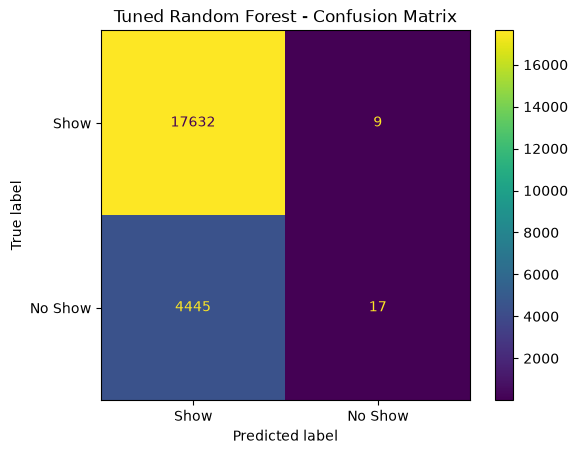

In [ ]:
#Plot Confusion Matrix

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best_rf,
    display_labels=["Show", "No Show"]
)

disp.plot()
plt.title("Tuned Random Forest - Confusion Matrix")
plt.show()

# 48. FINAL MODEL COMPARISON

In this step, the final performance of all trained models is compared using Accuracy, Precision, Recall, and F1 Score. The comparison includes Logistic Regression, Decision Tree, Random Forest, and the Tuned Random Forest model. The results are combined into a single DataFrame and rounded to four decimal places for clear and consistent comparison.

In [ ]:
#48.FINAL MODEL COMPARISON

final_comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Tuned Random Forest"
    ],

    "Accuracy": [
        accuracy_lr,
        accuracy_dt,
        accuracy_rf,
        accuracy_best_rf
    ],

    "Precision": [
        precision_lr,
        precision_dt,
        precision_rf,
        precision_best_rf
    ],

    "Recall": [
        recall_lr,
        recall_dt,
        recall_rf,
        recall_best_rf
    ],

    "F1 Score": [
        f1_lr,
        f1_dt,
        f1_rf,
        f1_best_rf
    ]
})

#Round values to 4 decimal places
final_comparison = final_comparison.round(4)

#Display DataFrame
final_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.7950,0.3365,0.0159,0.0304
1,Decision Tree,0.7961,0.4520,0.0464,0.0841
2,Random Forest,0.7981,0.0000,0.0000,0.0000
3,Tuned Random Forest,0.7985,0.6538,0.0038,0.0076


# 49. SELECT FINAL MODEL

In this step, the final best-performing model is selected based on the highest F1 Score from the final model comparison. The `idxmax()` function identifies the index of the model with the highest F1 Score. The selected model name and its F1 Score are then stored in a DataFrame and displayed as the final model selection.

In [ ]:
#49.SELECT FINAL MODEL

best_index = final_comparison["F1 Score"].idxmax()

best_model_name = final_comparison.loc[
    best_index,
    "Model"
]

best_f1_score = final_comparison.loc[
    best_index,
    "F1 Score"
]

#Create DataFrame for final model selection
df_final_model = pd.DataFrame({
    "Final Best Model": [best_model_name],
    "Final Best F1 Score": [round(best_f1_score, 4)]
})

#Display DataFrame
df_final_model

,Final Best Model,Final Best F1 Score
0,Decision Tree,0.0841


# 50. CREATE NEW OBSERVATION

In this step, a new patient appointment observation is created using a Pandas DataFrame. The observation contains the required demographic, medical, appointment, and waiting-time features that were used during model training. This new observation will be used later to make a prediction using the selected final model.

In [ ]:
#50.CREATE NEW OBSERVATION

new_data = pd.DataFrame({
    "gender": [0],
    "age": [35],
    "neighbourhood": ["JARDIM DA PENHA"],
    "scholarship": [0],
    "hipertension": [0],
    "diabetes": [0],
    "alcoholism": [0],
    "handcap": [0],
    "sms_received": [1],
    "appointment_year": [2016],
    "appointment_month": [5],
    "appointment_day": [10],
    "appointment_dayofweek": [1],
    "waiting_days": [10]
})

#Display new observation
new_data

,gender,age,neighbourhood,scholarship,hipertension,diabetes,alcoholism,handcap,sms_received,appointment_year,appointment_month,appointment_day,appointment_dayofweek,waiting_days
0,0,35,JARDIM DA PENHA,0,0,0,0,0,1,2016,5,10,1,10


# 51. PREPROCESS NEW OBSERVATION

In this step, the new observation is transformed using the same preprocessing pipeline that was fitted on the training data. This ensures that the numerical features are standardized and the categorical feature is encoded in the same way as the training data. The number of processed rows and columns is displayed to verify the preprocessing result.

In [ ]:
#51.PREPROCESS NEW OBSERVATION

new_data_processed = preprocessor.transform(new_data)

#Display preprocessing result using DataFrame
df_new_data_status = pd.DataFrame({
    "Status": ["New observation preprocessed successfully"],
    "Processed Rows": [new_data_processed.shape[0]],
    "Processed Columns": [new_data_processed.shape[1]]
})

df_new_data_status

,Status,Processed Rows,Processed Columns
0,New observation preprocessed successfully,1,94


# 52. PREDICT NEW OBSERVATION

In this step, the selected best Random Forest model is used to predict whether the new patient appointment is likely to be attended or missed. The model returns `0` for `Show` and `1` for `No Show`. The numerical prediction is converted into a meaningful result and displayed in a DataFrame.

In [ ]:
#52.PREDICT NEW OBSERVATION

new_prediction = best_rf_model.predict(
    new_data_processed
)

#Determine prediction result
if new_prediction[0] == 1:
    result = "NO SHOW"
else:
    result = "SHOW"

#Create DataFrame
df_new_prediction = pd.DataFrame({
    "Prediction": [new_prediction[0]],
    "Result": [result]
})

#Display DataFrame
df_new_prediction

,Prediction,Result
0,0,SHOW


# 53. PREDICTION PROBABILITY

In this step, the probability of each possible outcome for the new observation is calculated using the `predict_proba()` function of the tuned Random Forest model. The probabilities for `Show` and `No Show` are converted into percentages and rounded to two decimal places. The results are displayed in a DataFrame for easier interpretation.

In [ ]:
#53.PREDICTION PROBABILITY

new_probability = best_rf_model.predict_proba(
    new_data_processed
)

#Create DataFrame for prediction probabilities
df_prediction_probability = pd.DataFrame({
    "Outcome": [
        "Show",
        "No Show"
    ],
    "Probability (%)": [
        round(new_probability[0][0] * 100, 2),
        round(new_probability[0][1] * 100, 2)
    ]
})

#Display DataFrame
df_prediction_probability

,Outcome,Probability (%)
0,Show,72.02
1,No Show,27.98
